# Credit Score Project: Gartner Analytics Ascendancy x TDSP

This notebook runs the integrated framework end to end for a retail credit-scoring (probability of default) project.
Every stage has an explicit **Input -> Processing -> Output**, and each Gartner analytics tier enhances the TDSP stage it serves.

| TDSP stage | Gartner tier | Question | Notebook section |
|---|---|---|---|
| 1. Business understanding | scoping | What decision must improve? | Section 1 |
| 2. Data acquisition and understanding | foundation | What data can we trust? | Section 2 |
| 3A. Modeling | Descriptive | What happened? | Section 3A |
| 3B. Modeling | Diagnostic | Why did it happen? | Section 3B |
| 3C. Modeling | Predictive | Who will default? | Section 3C |
| 3D. Modeling | Prescriptive | Whom do we approve, at what price? | Section 3D |
| 4. Deployment | operationalize | How do we run it safely? | Section 4 |
| 5. Customer acceptance | validate | Does it meet the Stage 1 criteria? | Section 5 |

**Data note:** the notebook runs on a synthetic loan book by default so it works anywhere. To use real data, set `CONFIG["use_synthetic"] = False` and point `csv_path` at a file with the columns listed in Section 2.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.model_selection import TimeSeriesSplit

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})

SEED = 42

CONFIG = {
    # data
    "use_synthetic": True,
    "csv_path": "credit_applications.csv",
    "n_applicants": 40000,
    "target": "default_12m",          # 1 = default within 12 months of origination
    "date_col": "application_date",
    # time-based split (no random splits on time-ordered data)
    "train_end": "2022-12-31",
    "valid_end": "2023-06-30",
    # modeling
    "n_bins": 6,
    "iv_min": 0.02,
    "corr_max": 0.80,
    # scorecard scaling: 600 points at 50:1 good:bad odds, 20 points to double the odds
    "base_score": 600, "base_odds": 50, "pdo": 20,
    # economics (share of loan amount)
    "lgd": 0.60, "net_margin": 0.10,
    # policy constraints
    "min_approval_rate": 0.40, "max_bad_rate_approved": 0.07,
    "artifact_dir": "artifacts",
}
TARGET, DATE = CONFIG["target"], CONFIG["date_col"]

---
## Section 1. Business understanding (TDSP stage 1)

| | Content |
|---|---|
| **Input** | Lending mandate, risk appetite, regulatory constraints, stakeholder needs (credit, risk, compliance), existing approval rules |
| **Processing** | Translate the mandate into one measurable question per analytics tier; set KPIs and acceptance thresholds; define economics (LGD, margin) |
| **Output** | Project charter, KPI tree, tier-by-tier question list, acceptance criteria used again in Section 5 |

In [2]:
TIER_QUESTIONS = pd.DataFrame([
    ["Descriptive",  "What is our default rate and how is the book distributed?", "Baseline metrics to beat"],
    ["Diagnostic",   "Which borrower attributes drive default, and are they stable?", "Driver ranking, IV, PSI"],
    ["Predictive",   "What is each applicant's 12-month probability of default?", "AUC, KS, calibration"],
    ["Prescriptive", "What cutoff and pricing maximize profit within risk limits?", "Profit, approval rate, bad rate"],
], columns=["Tier", "Business question", "Success metric"])
display(TIER_QUESTIONS)

# Acceptance criteria are fixed NOW and tested in Section 5
ACCEPTANCE = {
    "test_auc_min": 0.70,             # discrimination on out-of-time data
    "test_ks_min": 0.30,
    "auc_gap_train_test_max": 0.03,   # overfitting guard
    "auc_uplift_vs_baseline_min": 0.03,
    "calibration_gap_max": 0.01,      # |mean PD - observed default rate|
    "score_psi_max": 0.25,            # population stability on the test period
    "approved_bad_rate_max": CONFIG["max_bad_rate_approved"],
    "profit_uplift_vs_approve_all_min": 0.0,
}
ACCEPTANCE

,Tier,Business question,Success metric
0,Descriptive,What is our default rate and how is the book d...,Baseline metrics to beat
1,Diagnostic,"Which borrower attributes drive default, and a...","Driver ranking, IV, PSI"
2,Predictive,What is each applicant's 12-month probability ...,"AUC, KS, calibration"
3,Prescriptive,What cutoff and pricing maximize profit within...,"Profit, approval rate, bad rate"


{'test_auc_min': 0.7,
 'test_ks_min': 0.3,
 'auc_gap_train_test_max': 0.03,
 'auc_uplift_vs_baseline_min': 0.03,
 'calibration_gap_max': 0.01,
 'score_psi_max': 0.25,
 'approved_bad_rate_max': 0.07,
 'profit_uplift_vs_approve_all_min': 0.0}

---
## Section 2. Data acquisition and understanding (TDSP stage 2)

| | Content |
|---|---|
| **Input** | Application data, bureau attributes, loan terms, 12-month default outcome |
| **Processing** | Ingest, deduplicate, quality checks, point-in-time discipline, feature engineering, time-ordered split |
| **Output** | Versioned analysis-ready train / validation / out-of-time test sets, data quality report, go/no-go on data sufficiency |

Expected columns for real data: `applicant_id`, `application_date`, `age`, `income`, `employment_years`, `credit_history_years`,
`debt_to_income`, `credit_utilization`, `num_delinquencies_2y`, `num_inquiries_6m`, `num_open_accounts`, `loan_amount`, `loan_term`, `home_ownership`, `default_12m`.

Point-in-time rule: every feature must be known at application date. The outcome is observed 12 months later, so the split below is by application date.

In [3]:
def make_synthetic_credit_data(n, seed=SEED):
    # Synthetic retail loan book, 2021-01 to 2024-06, with a mild utilization drift from 2023-07
    r = np.random.default_rng(seed)
    dates = pd.to_datetime("2021-01-01") + pd.to_timedelta(r.integers(0, 1277, n), unit="D")
    drift = np.asarray(dates >= pd.Timestamp("2023-07-01"), dtype=float)

    age = np.clip(r.normal(40, 11, n), 21, 75).round()
    income = np.exp(r.normal(10.9, 0.5, n))
    employment_years = np.clip(r.gamma(2.0, 3.0, n), 0, 40)
    credit_history_years = np.clip(age - 20 - r.exponential(4, n), 0.5, 50)
    dti = np.clip(r.beta(2.2, 5, n), 0, 0.95)
    util = np.clip(r.beta(2, 3, n) + 0.06 * drift, 0, 1)
    delinq = r.poisson(0.25 + 1.2 * dti)
    inquiries = r.poisson(1.2 + 1.5 * util)
    open_accts = r.poisson(6, n) + 1
    loan_amount = np.clip(income * r.uniform(0.1, 0.6, n), 1000, 80000).round(-2)
    term = r.choice([36, 60], n, p=[0.65, 0.35])
    home = r.choice(["RENT", "MORTGAGE", "OWN"], n, p=[0.45, 0.40, 0.15])

    logit = (-5.0 + 3.0 * dti + 1.8 * util + 0.45 * delinq + 0.10 * inquiries
             - 0.30 * np.log(income / 55000) - 0.035 * credit_history_years - 0.02 * employment_years
             + 0.45 * (term == 60) + 0.30 * (home == "RENT") - 0.25 * (home == "OWN")
             - 0.008 * (age - 40) + 1.0 * (loan_amount / income) + r.normal(0, 0.35, n))
    default = (r.uniform(size=n) < 1 / (1 + np.exp(-logit))).astype(int)

    out = pd.DataFrame({
        "applicant_id": np.arange(1, n + 1), DATE: dates, "age": age, "income": income,
        "employment_years": employment_years, "credit_history_years": credit_history_years,
        "debt_to_income": dti, "credit_utilization": util, "num_delinquencies_2y": delinq,
        "num_inquiries_6m": inquiries, "num_open_accounts": open_accts, "loan_amount": loan_amount,
        "loan_term": term, "home_ownership": home, TARGET: default,
    })
    # realistic data problems: missing values and a few duplicate records
    out.loc[r.uniform(size=n) < 0.03, "income"] = np.nan
    out.loc[r.uniform(size=n) < 0.05, "employment_years"] = np.nan
    return pd.concat([out, out.sample(60, random_state=seed)], ignore_index=True)


def load_data(cfg):
    if cfg["use_synthetic"]:
        return make_synthetic_credit_data(cfg["n_applicants"])
    return pd.read_csv(cfg["csv_path"], parse_dates=[cfg["date_col"]])


raw = load_data(CONFIG)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (40060, 15)


,applicant_id,application_date,age,income,employment_years,credit_history_years,debt_to_income,credit_utilization,num_delinquencies_2y,num_inquiries_6m,num_open_accounts,loan_amount,loan_term,home_ownership,default_12m
0,1,2021-04-24,21.0000,"47,579.2099",7.6842,0.5000,0.4513,0.5759,2,2,10,"17,200.0000",36,OWN,0
1,2,2023-09-16,36.0000,"52,621.0720",1.0190,10.7998,0.2815,0.7096,0,2,11,"9,300.0000",36,MORTGAGE,0
2,3,2023-04-16,21.0000,"132,447.0303",12.9476,0.5000,0.1644,0.4276,0,2,10,"19,400.0000",36,RENT,0
3,4,2022-07-15,62.0000,"88,005.0340",4.3334,41.7913,0.3644,0.2542,0,2,3,"22,600.0000",36,MORTGAGE,0
4,5,2022-07-07,42.0000,"45,343.7018",10.8759,16.0381,0.4515,0.2255,1,2,5,"15,700.0000",60,MORTGAGE,0


In [4]:
# ---- Data quality report
dq = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_%": raw.isna().mean() * 100,
    "n_unique": raw.nunique(),
})
display(dq)

print("Duplicate applicant_id rows:", int(raw.duplicated("applicant_id").sum()))
print("Date range:", raw[DATE].min().date(), "->", raw[DATE].max().date())

range_checks = {
    "age": (18, 100), "income": (0, 5e7), "debt_to_income": (0, 1.5), "credit_utilization": (0, 1.5),
    "loan_amount": (0, 5e6), "num_delinquencies_2y": (0, 50),
}
violations = {c: int(((raw[c] < lo) | (raw[c] > hi)).sum()) for c, (lo, hi) in range_checks.items()}
print("Range violations:", violations)

go_no_go = (raw[TARGET].notna().all() and raw[TARGET].mean() > 0.01 and sum(violations.values()) == 0)
print("Data sufficiency go/no-go:", "GO" if go_no_go else "NO-GO")

,dtype,missing_%,n_unique
applicant_id,int64,0.0000,40000
application_date,datetime64[us],0.0000,1277
age,float64,0.0000,55
income,float64,2.9880,38805
employment_years,float64,5.0624,37976
credit_history_years,float64,0.0000,36335
debt_to_income,float64,0.0000,40000
credit_utilization,float64,0.0000,39992
num_delinquencies_2y,int64,0.0000,7
num_inquiries_6m,int64,0.0000,10


Duplicate applicant_id rows: 60
Date range: 2021-01-01 -> 2024-06-30
Range violations: {'age': 0, 'income': 0, 'debt_to_income': 0, 'credit_utilization': 0, 'loan_amount': 0, 'num_delinquencies_2y': 0}
Data sufficiency go/no-go: GO


In [5]:
# ---- Clean, engineer, and split by time
df = raw.drop_duplicates("applicant_id").sort_values(DATE).reset_index(drop=True)
df["loan_to_income"] = df["loan_amount"] / df["income"]

NUM = ["age", "income", "employment_years", "credit_history_years", "debt_to_income",
       "credit_utilization", "num_delinquencies_2y", "num_inquiries_6m", "num_open_accounts",
       "loan_amount", "loan_to_income"]
CAT = ["loan_term", "home_ownership"]
FEATURES = NUM + CAT

train = df[df[DATE] <= CONFIG["train_end"]].copy()
valid = df[(df[DATE] > CONFIG["train_end"]) & (df[DATE] <= CONFIG["valid_end"])].copy()
test = df[df[DATE] > CONFIG["valid_end"]].copy()

# Leakage guards
assert TARGET not in FEATURES and DATE not in FEATURES
assert train[DATE].max() < valid[DATE].min() and valid[DATE].max() < test[DATE].min()

summary = pd.DataFrame({
    "rows": [len(train), len(valid), len(test)],
    "from": [d[DATE].min().date() for d in (train, valid, test)],
    "to": [d[DATE].max().date() for d in (train, valid, test)],
    "default_rate": [d[TARGET].mean() for d in (train, valid, test)],
}, index=["train", "validation", "out-of-time test"])
summary

,rows,from,to,default_rate
train,22900,2021-01-01,2022-12-31,0.0682
validation,5688,2023-01-01,2023-06-30,0.0730
out-of-time test,11412,2023-07-01,2024-06-30,0.0770


---
## Section 3A. Modeling: Descriptive analytics (What happened?)

| | Content |
|---|---|
| **Input** | Clean historical applications and outcomes (Section 2), KPI definitions (Section 1) |
| **Processing** | Aggregate, summarize, visualize; build a simple rule-based baseline |
| **Output** | Dashboards, baseline metrics every later model must beat, anomalies passed to diagnosis |

Default rate by segment (train)


,applicants,default_rate
loan_term,,
36,15071,0.0594
60,7829,0.0851


,applicants,default_rate
home_ownership,,
MORTGAGE,9317,0.0636
OWN,3329,0.0481
RENT,10254,0.0788


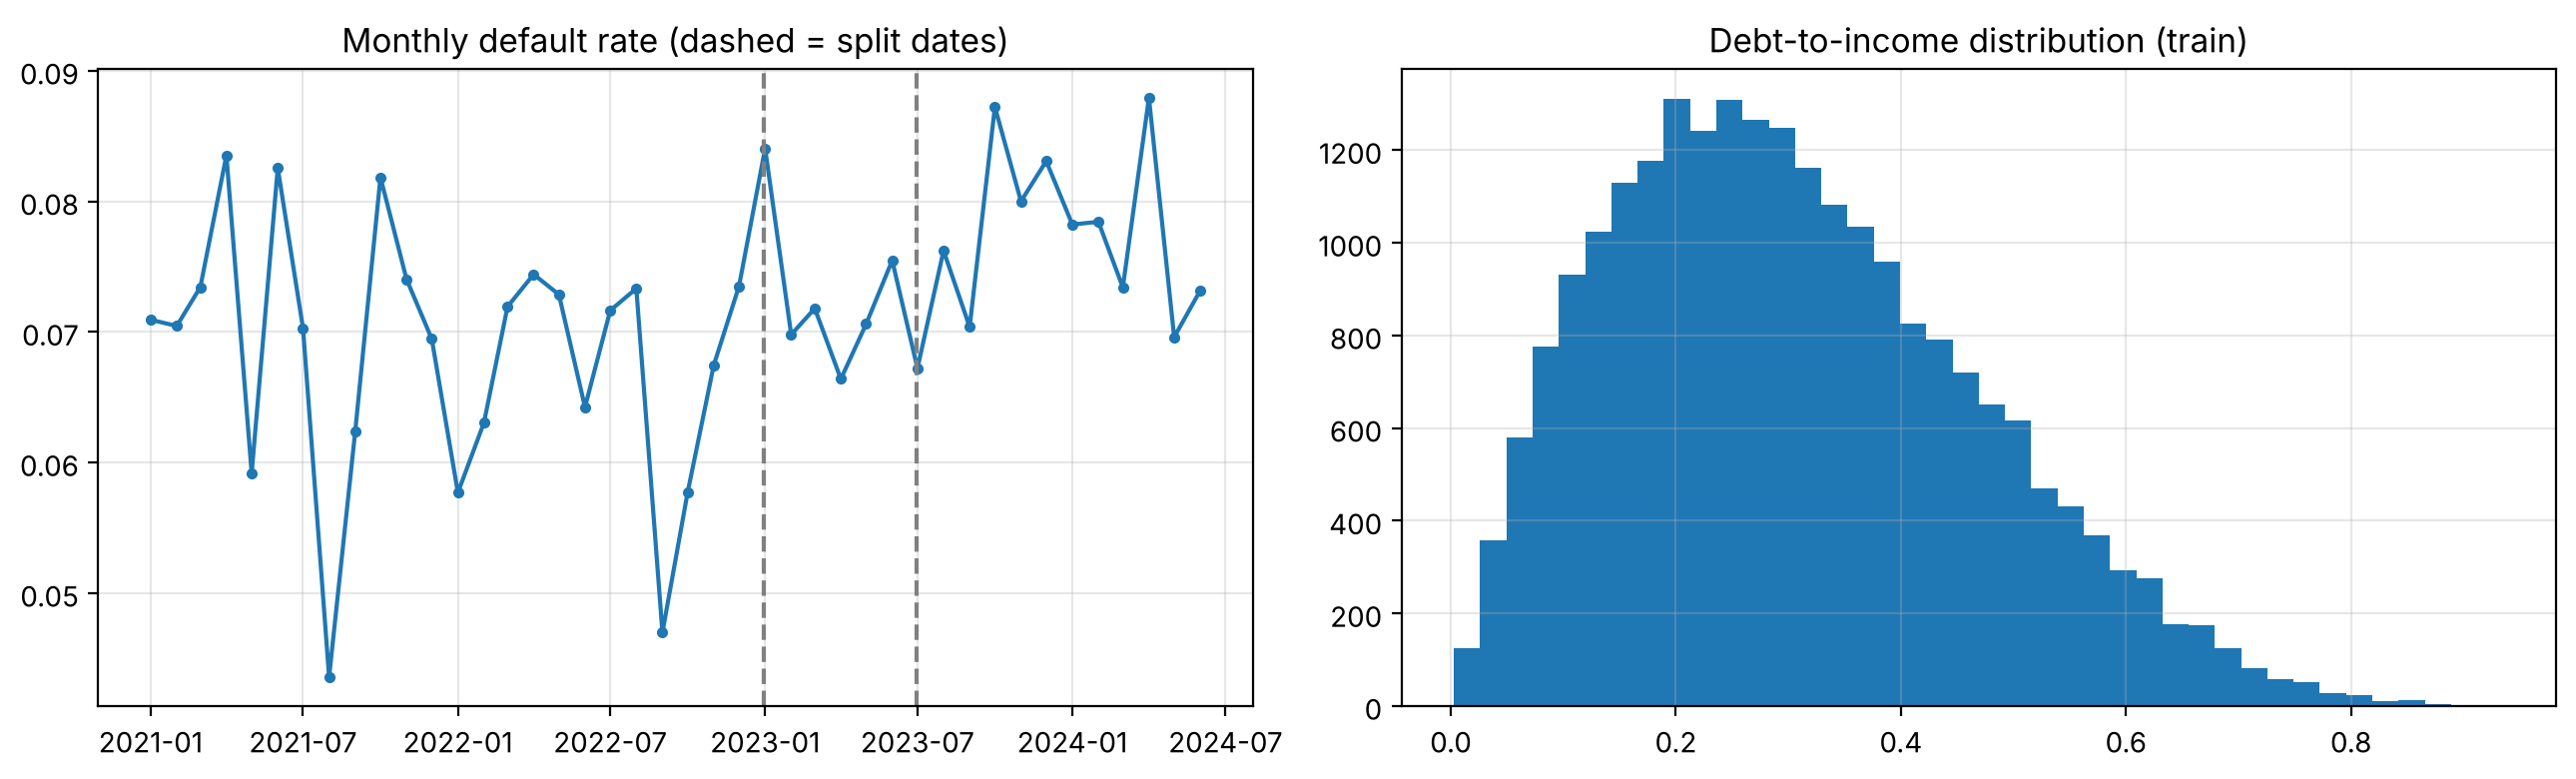

In [6]:
def ks_stat(y, risk):
    fpr, tpr, _ = roc_curve(y, risk)
    return float(np.max(tpr - fpr))


def evaluate(y, risk):
    # risk: higher value = riskier applicant
    auc = roc_auc_score(y, risk)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": ks_stat(y, risk)}


print("Default rate by segment (train)")
for c in ["loan_term", "home_ownership"]:
    display(train.groupby(c)[TARGET].agg(applicants="size", default_rate="mean"))

monthly = df.groupby(df[DATE].dt.to_period("M"))[TARGET].agg(["size", "mean"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(monthly.index.to_timestamp(), monthly["mean"], marker="o", ms=3)
ax[0].axvline(pd.Timestamp(CONFIG["train_end"]), color="gray", ls="--")
ax[0].axvline(pd.Timestamp(CONFIG["valid_end"]), color="gray", ls="--")
ax[0].set_title("Monthly default rate (dashed = split dates)")
train["debt_to_income"].hist(bins=40, ax=ax[1])
ax[1].set_title("Debt-to-income distribution (train)")
plt.tight_layout()
plt.show()

In [7]:
# Baseline: simple rule using three risk drivers (no model). Later tiers must beat it.
def baseline_risk(d):
    return (d["debt_to_income"].rank(pct=True)
            + d["credit_utilization"].rank(pct=True)
            + d["num_delinquencies_2y"].rank(pct=True)) / 3


BASELINE = pd.DataFrame({name: evaluate(d[TARGET], baseline_risk(d))
                         for name, d in {"train": train, "valid": valid, "test": test}.items()}).T
print("Baseline rule performance")
BASELINE

Baseline rule performance


,AUC,Gini,KS
train,0.6981,0.3962,0.2918
valid,0.7101,0.4203,0.3384
test,0.7064,0.4127,0.3072


---
## Section 3B. Modeling: Diagnostic analytics (Why did it happen?)

| | Content |
|---|---|
| **Input** | Descriptive outputs, anomalies, all candidate features |
| **Processing** | Weight of evidence (WoE) and information value (IV) per feature, correlation screening, population stability (PSI) |
| **Output** | Driver ranking, validated hypotheses about risk drivers, a stable candidate feature list for prediction |

WoE here is `ln(share of bads / share of goods)` per bin, so a **positive WoE means riskier**. Bins are fitted on the training set only.

,IV,strength
debt_to_income,0.2958,medium
num_delinquencies_2y,0.1857,medium
credit_history_years,0.1490,medium
age,0.1431,medium
credit_utilization,0.0930,weak
loan_term,0.0352,weak
home_ownership,0.0307,weak
num_inquiries_6m,0.0299,weak
income,0.0164,useless
loan_to_income,0.0112,useless


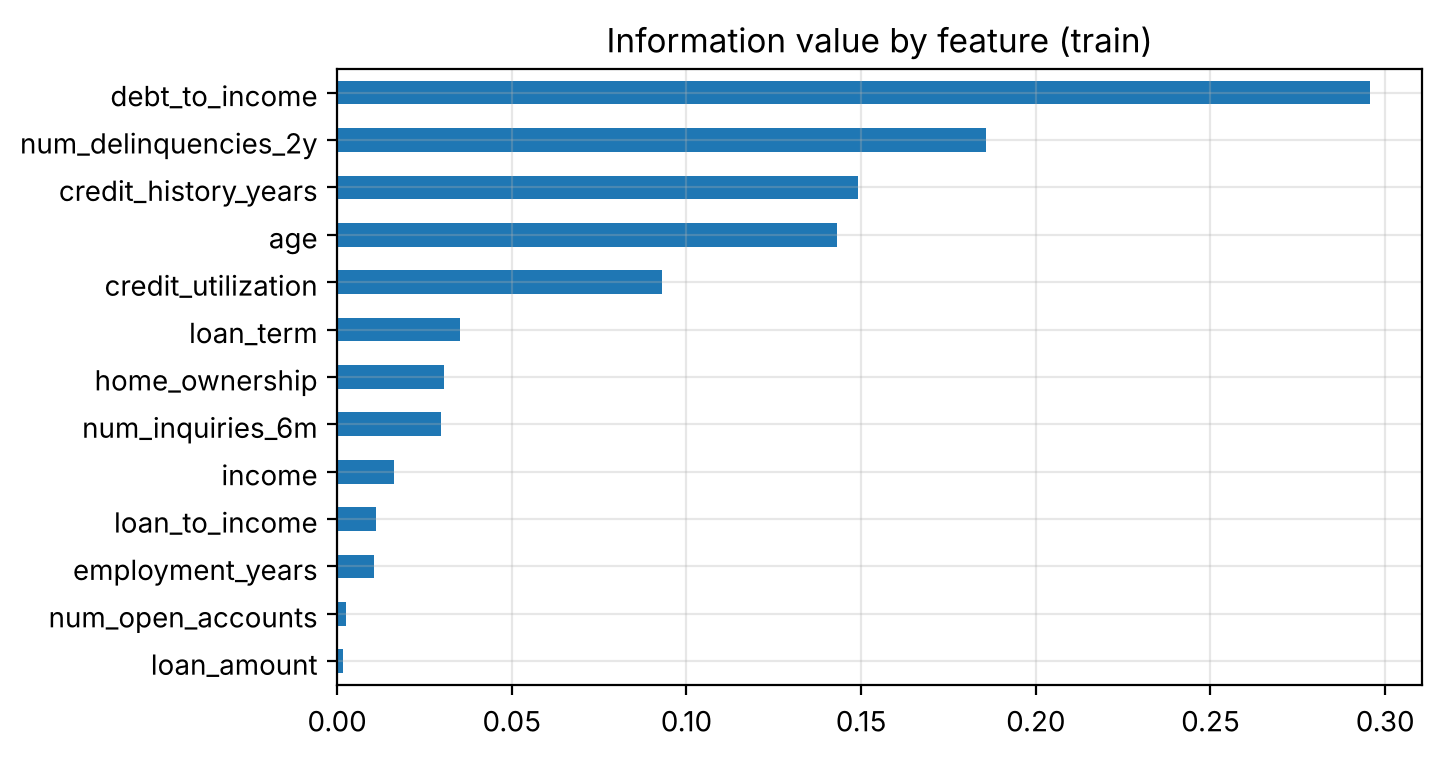

In [8]:
def bin_numeric(s, edges):
    # bin id -1 = missing, otherwise 0..len(edges)
    v = pd.to_numeric(s, errors="coerce").to_numpy(dtype=float)
    return np.where(np.isnan(v), -1, np.digitize(np.nan_to_num(v), np.asarray(edges, dtype=float))).astype(int)


def bin_categorical(s):
    return s.astype(object).where(s.notna(), "MISSING").astype(str).to_numpy()


class WoEEncoder:
    def __init__(self, n_bins=6, smoothing=0.5):
        self.n_bins, self.smoothing = n_bins, smoothing
        self.spec_ = {}

    def fit(self, X, y, num_cols, cat_cols):
        y = np.asarray(y)
        q = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        for c in num_cols:
            edges = np.unique(np.nanquantile(X[c].to_numpy(dtype=float), q))
            self.spec_[c] = self._table(bin_numeric(X[c], edges), y, "num", edges.tolist())
        for c in cat_cols:
            self.spec_[c] = self._table(bin_categorical(X[c]), y, "cat", None)
        return self

    def _table(self, bins, y, kind, edges):
        t = pd.DataFrame({"bin": bins.astype(str), "bad": y}).groupby("bin")["bad"].agg(n="size", bad="sum")
        t["good"] = t["n"] - t["bad"]
        k, s = len(t), self.smoothing
        dist_bad = (t["bad"] + s) / (t["bad"].sum() + s * k)
        dist_good = (t["good"] + s) / (t["good"].sum() + s * k)
        t["woe"] = np.log(dist_bad / dist_good)
        t["iv_part"] = (dist_bad - dist_good) * t["woe"]
        t["bad_rate"] = t["bad"] / t["n"]
        return {"kind": kind, "edges": edges, "table": t, "iv": float(t["iv_part"].sum())}

    def transform(self, X, cols=None):
        out = {}
        for c in (cols or list(self.spec_)):
            sp = self.spec_[c]
            b = bin_numeric(X[c], sp["edges"]) if sp["kind"] == "num" else bin_categorical(X[c])
            m = sp["table"]["woe"].to_dict()
            out[c] = pd.Series(b.astype(str), index=X.index).map(m).fillna(0.0).to_numpy()
        return pd.DataFrame(out, index=X.index)


def bin_label(sp, key):
    if sp["kind"] == "cat":
        return str(key)
    k, e = int(key), sp["edges"]
    if k == -1:
        return "Missing"
    if len(e) == 0:
        return "all"
    if k == 0:
        return f"< {e[0]:.4g}"
    if k == len(e):
        return f">= {e[-1]:.4g}"
    return f"[{e[k-1]:.4g}, {e[k]:.4g})"


def ordered_table(enc, c):
    t = enc.spec_[c]["table"]
    return t.loc[sorted(t.index, key=int)] if enc.spec_[c]["kind"] == "num" else t


enc = WoEEncoder(CONFIG["n_bins"]).fit(train, train[TARGET], NUM, CAT)

IV = pd.Series({c: sp["iv"] for c, sp in enc.spec_.items()}, name="IV").sort_values(ascending=False).to_frame()
IV["strength"] = pd.cut(IV["IV"], [-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
                        labels=["useless", "weak", "medium", "strong", "suspicious"])
display(IV)

IV["IV"].sort_values().plot.barh(figsize=(7, 4), title="Information value by feature (train)")
plt.show()

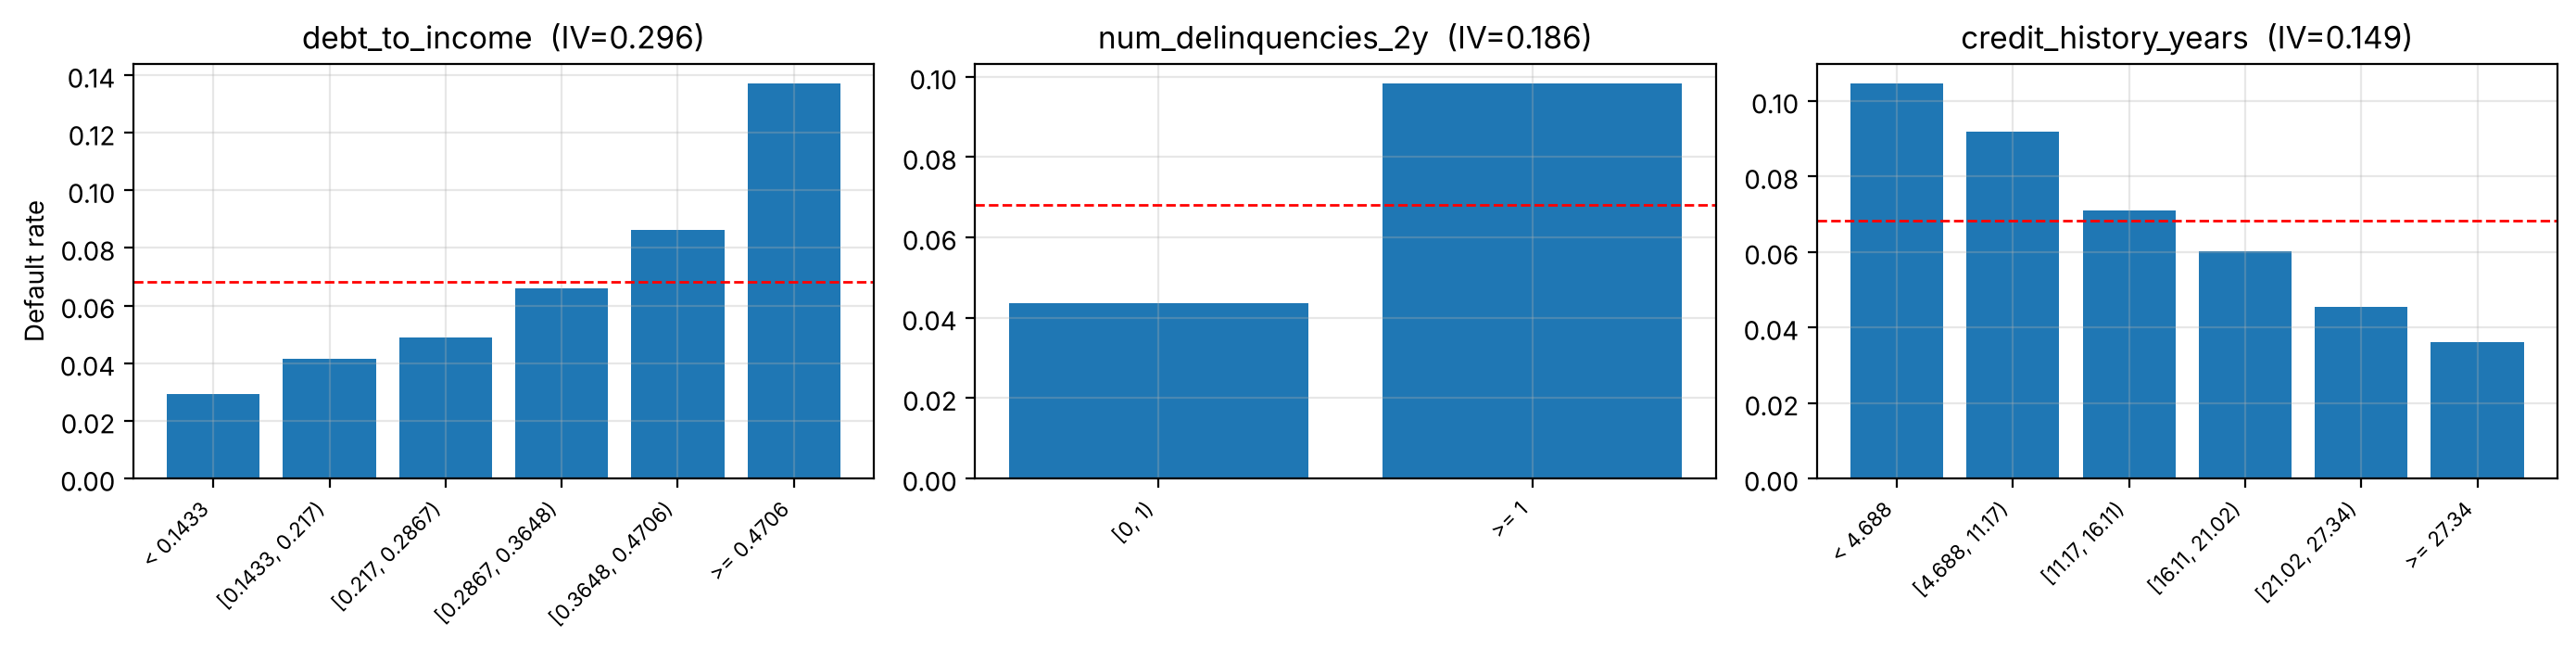

Dropped for low IV: ['income', 'loan_to_income', 'employment_years', 'num_open_accounts', 'loan_amount']
Dropped for correlation: ['age']
Candidate features: ['debt_to_income', 'num_delinquencies_2y', 'credit_history_years', 'credit_utilization', 'loan_term', 'home_ownership', 'num_inquiries_6m']


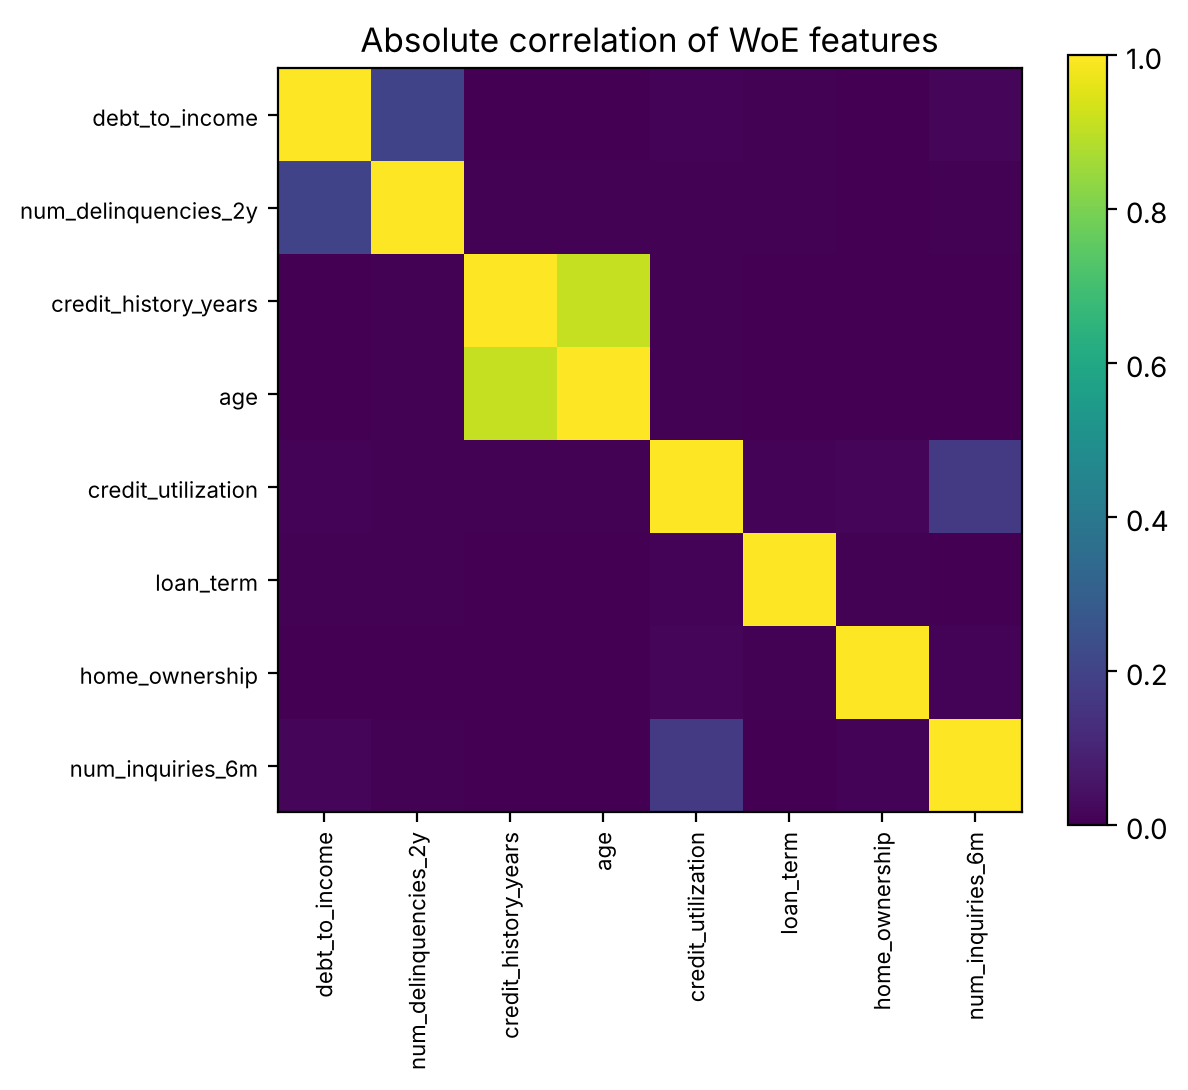

In [9]:
# Default rate by bin for the top drivers
top = list(IV.index[:3])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, c in zip(axes, top):
    t = ordered_table(enc, c)
    labels = [bin_label(enc.spec_[c], k) for k in t.index]
    ax.bar(range(len(t)), t["bad_rate"])
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.axhline(train[TARGET].mean(), color="red", ls="--", lw=1)
    ax.set_title(f"{c}  (IV={enc.spec_[c]['iv']:.3f})")
axes[0].set_ylabel("Default rate")
plt.tight_layout()
plt.show()

# Feature selection: IV threshold, then drop highly correlated WoE features (keep higher IV)
cands = [c for c in IV.index if IV.loc[c, "IV"] >= CONFIG["iv_min"]]
woe_train = enc.transform(train, cands)
corr = woe_train.corr().abs()

selected = []
for c in cands:
    if all(corr.loc[c, k] < CONFIG["corr_max"] for k in selected):
        selected.append(c)

dropped_corr = [c for c in cands if c not in selected]
print("Dropped for low IV:", [c for c in IV.index if c not in cands])
print("Dropped for correlation:", dropped_corr)
print("Candidate features:", selected)

plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="viridis", vmin=0, vmax=1)
plt.xticks(range(len(cands)), cands, rotation=90, fontsize=8)
plt.yticks(range(len(cands)), cands, fontsize=8)
plt.colorbar()
plt.title("Absolute correlation of WoE features")
plt.grid(False)
plt.show()

In [10]:
# Population stability: has the applicant mix moved between train and the out-of-time test?
def psi_from_props(p_exp, p_act, eps=1e-4):
    p_exp, p_act = np.clip(p_exp, eps, None), np.clip(p_act, eps, None)
    return float(np.sum((p_act - p_exp) * np.log(p_act / p_exp)))


def psi_numeric(ref, cur, n_bins=10):
    ref, cur = pd.Series(ref), pd.Series(cur)
    q = np.linspace(0, 1, n_bins + 1)[1:-1]
    edges = np.unique(np.nanquantile(ref.to_numpy(dtype=float), q))
    b_ref, b_cur = bin_numeric(ref, edges), bin_numeric(cur, edges)
    ids = np.arange(-1, len(edges) + 1)
    return psi_from_props(np.array([(b_ref == i).mean() for i in ids]),
                          np.array([(b_cur == i).mean() for i in ids]))


def psi_categorical(ref, cur):
    b_ref, b_cur = bin_categorical(pd.Series(ref)), bin_categorical(pd.Series(cur))
    cats = np.union1d(b_ref, b_cur)
    return psi_from_props(np.array([(b_ref == c).mean() for c in cats]),
                          np.array([(b_cur == c).mean() for c in cats]))


def feature_psi(ref, cur, feats):
    return pd.Series({c: (psi_numeric(ref[c], cur[c]) if enc.spec_[c]["kind"] == "num"
                          else psi_categorical(ref[c], cur[c])) for c in feats})


psi_tbl = feature_psi(train, test, FEATURES).sort_values(ascending=False).rename("PSI train vs test").to_frame()
psi_tbl["flag"] = pd.cut(psi_tbl.iloc[:, 0], [-np.inf, 0.10, 0.25, np.inf], labels=["stable", "watch", "shift"])
psi_tbl

,PSI train vs test,flag
credit_utilization,0.1020,watch
num_inquiries_6m,0.0052,stable
age,0.0027,stable
credit_history_years,0.0022,stable
loan_to_income,0.0018,stable
loan_amount,0.0015,stable
num_open_accounts,0.0013,stable
employment_years,0.0012,stable
debt_to_income,0.0008,stable
home_ownership,0.0006,stable


---
## Section 3C. Modeling: Predictive analytics (Who will default?)

| | Content |
|---|---|
| **Input** | WoE features from the diagnostic stage, labeled 12-month default outcome |
| **Processing** | Logistic scorecard (champion), gradient boosting (challenger), walk-forward cross-validation, out-of-time testing, calibration check |
| **Output** | Validated PD model and points-based scorecard, model performance table, model card inputs |

The scorecard is the champion because it is transparent and easy to audit. The challenger only replaces it if it adds clear lift.

In [11]:
# ---- Fit logistic regression on WoE features; drop any feature whose coefficient has the wrong sign
SELECTED = list(selected)


def fit_lr(feats):
    return LogisticRegression(C=1.0, max_iter=1000).fit(enc.transform(train, feats), train[TARGET])


lr = fit_lr(SELECTED)
while (lr.coef_[0] <= 0).any():          # risk-WoE should carry positive coefficients
    worst = SELECTED[int(np.argmin(lr.coef_[0]))]
    print("Dropping (wrong sign):", worst)
    SELECTED.remove(worst)
    lr = fit_lr(SELECTED)

print("Final features:", SELECTED)
pd.Series(lr.coef_[0], index=SELECTED, name="coefficient").to_frame()

Final features: ['debt_to_income', 'num_delinquencies_2y', 'credit_history_years', 'credit_utilization', 'loan_term', 'home_ownership', 'num_inquiries_6m']


,coefficient
debt_to_income,0.9118
num_delinquencies_2y,0.8030
credit_history_years,1.0456
credit_utilization,0.9832
loan_term,0.9759
home_ownership,1.0354
num_inquiries_6m,0.7432


In [12]:
# ---- Walk-forward cross-validation inside the training period (never random folds on time series)
tscv = TimeSeriesSplit(n_splits=4)
rows = []
for i, (a, b) in enumerate(tscv.split(train), 1):
    tr, va = train.iloc[a], train.iloc[b]
    e = WoEEncoder(CONFIG["n_bins"]).fit(tr, tr[TARGET], NUM, CAT)   # refit bins on each fold's past only
    m = LogisticRegression(C=1.0, max_iter=1000).fit(e.transform(tr, SELECTED), tr[TARGET])
    rows.append({"fold": i, "train_rows": len(tr), **evaluate(va[TARGET], m.predict_proba(e.transform(va, SELECTED))[:, 1])})
cv = pd.DataFrame(rows)
display(cv)
print(f"CV AUC mean {cv['AUC'].mean():.4f}  std {cv['AUC'].std():.4f}")

,fold,train_rows,AUC,Gini,KS
0,1,4580,0.7212,0.4425,0.3204
1,2,9160,0.7457,0.4914,0.3815
2,3,13740,0.6860,0.3720,0.2899
3,4,18320,0.7419,0.4838,0.3735


CV AUC mean 0.7237  std 0.0273


In [13]:
# ---- Scorecard scaling and packaging
FACTOR = CONFIG["pdo"] / np.log(2)
OFFSET = CONFIG["base_score"] - FACTOR * np.log(CONFIG["base_odds"])
SCORE_FLOOR, SCORE_CAP = 300, 850


class ScorecardModel:
    def __init__(self, spec):
        self.spec = spec

    @classmethod
    def from_json(cls, path):
        return cls(json.loads(Path(path).read_text()))

    def woe_frame(self, X):
        cols = {}
        for c, f in self.spec["features"].items():
            b = bin_numeric(X[c], f["edges"]) if f["kind"] == "num" else bin_categorical(X[c])
            cols[c] = pd.Series(b.astype(str), index=X.index).map(f["woe"]).fillna(0.0).to_numpy()
        return pd.DataFrame(cols, index=X.index)

    def logit(self, X):
        W = self.woe_frame(X)
        return self.spec["intercept"] + sum(W[c] * self.spec["coef"][c] for c in W.columns)

    def predict_pd(self, X):
        return 1.0 / (1.0 + np.exp(-self.logit(X)))

    def score(self, X):
        raw_score = self.spec["offset"] - self.spec["factor"] * self.logit(X)
        return np.clip(raw_score, self.spec["floor"], self.spec["cap"])


spec = {
    "features": {c: {"kind": enc.spec_[c]["kind"], "edges": enc.spec_[c]["edges"],
                     "woe": {k: float(v) for k, v in enc.spec_[c]["table"]["woe"].items()}} for c in SELECTED},
    "coef": {c: float(v) for c, v in zip(SELECTED, lr.coef_[0])},
    "intercept": float(lr.intercept_[0]),
    "factor": float(FACTOR), "offset": float(OFFSET), "floor": SCORE_FLOOR, "cap": SCORE_CAP,
}
model = ScorecardModel(spec)

for d in (train, valid, test):
    d["pd"] = model.predict_pd(d)
    d["score"] = model.score(d)

# ---- Points table (what a credit officer reads)
k = len(SELECTED)
base_pts = (OFFSET - FACTOR * spec["intercept"]) / k
rows = []
for c in SELECTED:
    for key, r in ordered_table(enc, c).iterrows():
        rows.append({"feature": c, "bin": bin_label(enc.spec_[c], key), "applicants": int(r["n"]),
                     "default_rate": r["bad_rate"], "woe": r["woe"],
                     "points": base_pts - FACTOR * spec["coef"][c] * r["woe"]})
SCORECARD_TABLE = pd.DataFrame(rows)

# Consistency check: sum of points equals the scaled score before clipping
W = model.woe_frame(train.head(1000))
pts_sum = sum(base_pts - FACTOR * spec["coef"][c] * W[c] for c in SELECTED)
assert np.allclose(pts_sum, OFFSET - FACTOR * model.logit(train.head(1000)))

print(f"Score range on train: {train['score'].min():.0f} to {train['score'].max():.0f}")
SCORECARD_TABLE

Score range on train: 491 to 648


,feature,bin,applicants,default_rate,woe,points
0,debt_to_income,< 0.1433,3817,0.0293,-0.8812,103.5471
1,debt_to_income,"[0.1433, 0.217)",3816,0.0414,-0.5256,94.1921
2,debt_to_income,"[0.217, 0.2867)",3817,0.0490,-0.3499,89.5692
3,debt_to_income,"[0.2867, 0.3648)",3816,0.0660,-0.0339,81.2556
4,debt_to_income,"[0.3648, 0.4706)",3817,0.0862,0.2538,73.6857
5,debt_to_income,>= 0.4706,3817,0.1370,0.7740,59.9996
6,num_delinquencies_2y,"[0, 1)",12601,0.0436,-0.4734,91.3309
7,num_delinquencies_2y,>= 1,10299,0.0983,0.3984,71.1330
8,credit_history_years,< 4.688,3817,0.1045,0.4667,66.2832
9,credit_history_years,"[4.688, 11.17)",3816,0.0917,0.3219,70.6516


In [14]:
# ---- Challenger: gradient boosting on raw features
HOME_MAP = {"RENT": 0, "MORTGAGE": 1, "OWN": 2}


def gbm_matrix(d):
    X = d[NUM].copy()
    X["loan_term"] = d["loan_term"].astype(float)
    X["home_ownership"] = d["home_ownership"].map(HOME_MAP).astype(float)
    return X


gbm = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=250,
                                     l2_regularization=1.0, random_state=SEED).fit(gbm_matrix(train), train[TARGET])
for d in (train, valid, test):
    d["pd_gbm"] = gbm.predict_proba(gbm_matrix(d))[:, 1]

models = {"Baseline rule": lambda d: baseline_risk(d),
          "Scorecard (champion)": lambda d: d["pd"],
          "GBM (challenger)": lambda d: d["pd_gbm"]}
rows = []
for name, fn in models.items():
    for split, d in (("train", train), ("valid", valid), ("test", test)):
        rows.append({"model": name, "split": split, **evaluate(d[TARGET], fn(d)),
                     "Brier": brier_score_loss(d[TARGET], d["pd"]) if name.startswith("Score") else np.nan})
PERF = pd.DataFrame(rows)
display(PERF.pivot(index="model", columns="split", values="AUC")[["train", "valid", "test"]])
display(PERF[PERF["split"] == "test"].set_index("model")[["AUC", "Gini", "KS", "Brier"]])

gain = (PERF.query("model == 'GBM (challenger)' and split == 'valid'")["AUC"].iloc[0]
        - PERF.query("model == 'Scorecard (champion)' and split == 'valid'")["AUC"].iloc[0])
print(f"Challenger AUC gain on validation: {gain:+.4f}")
print("Decision:", "review challenger (gain > 0.02)" if gain > 0.02 else "keep scorecard as champion (gain too small to justify opacity)")

split,train,valid,test
model,,,
Baseline rule,0.6981,0.7101,0.7064
GBM (challenger),0.7812,0.7571,0.7410
Scorecard (champion),0.7319,0.7483,0.7324


,AUC,Gini,KS,Brier
model,,,,
Baseline rule,0.7064,0.4127,0.3072,NaN
Scorecard (champion),0.7324,0.4647,0.3412,0.0663
GBM (challenger),0.7410,0.4821,0.3668,NaN


Challenger AUC gain on validation: +0.0087
Decision: keep scorecard as champion (gain too small to justify opacity)


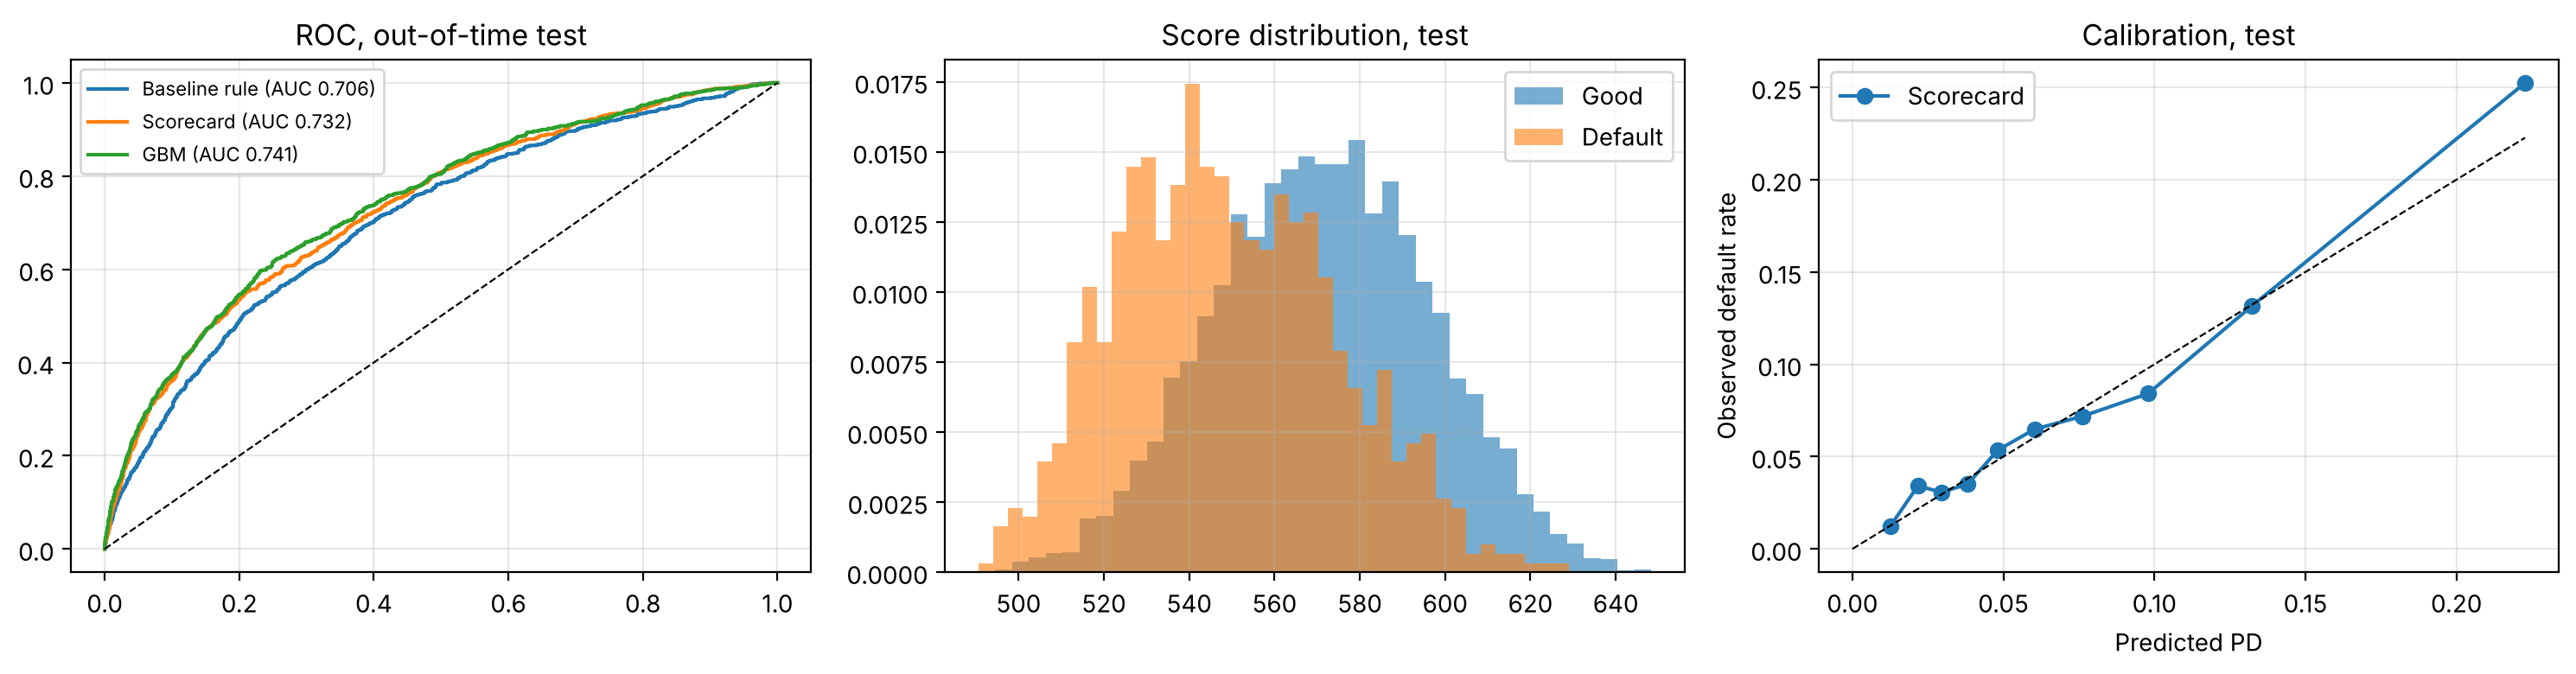

Test: mean predicted PD 0.0739 vs observed default rate 0.0770


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for name, risk in [("Baseline rule", baseline_risk(test)), ("Scorecard", test["pd"]), ("GBM", test["pd_gbm"])]:
    fpr, tpr, _ = roc_curve(test[TARGET], risk)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(test[TARGET], risk):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_title("ROC, out-of-time test"); ax[0].legend(fontsize=8)

ax[1].hist(test.loc[test[TARGET] == 0, "score"], bins=40, alpha=0.6, density=True, label="Good")
ax[1].hist(test.loc[test[TARGET] == 1, "score"], bins=40, alpha=0.6, density=True, label="Default")
ax[1].set_title("Score distribution, test"); ax[1].legend()

obs, pred = calibration_curve(test[TARGET], test["pd"], n_bins=10, strategy="quantile")
ax[2].plot(pred, obs, marker="o", label="Scorecard")
ax[2].plot([0, pred.max()], [0, pred.max()], "k--", lw=0.8)
ax[2].set_xlabel("Predicted PD"); ax[2].set_ylabel("Observed default rate")
ax[2].set_title("Calibration, test"); ax[2].legend()
plt.tight_layout()
plt.show()

print(f"Test: mean predicted PD {test['pd'].mean():.4f} vs observed default rate {test[TARGET].mean():.4f}")

---
## Section 3D. Modeling: Prescriptive analytics (What should we do?)

| | Content |
|---|---|
| **Input** | PD and score from Section 3C, economics (LGD, margin), policy limits (minimum approval rate, maximum approved bad rate) |
| **Processing** | Profit-maximizing cutoff scan on validation data, constrained by policy limits; sensitivity to LGD and margin; stress test on PD; risk-based pricing bands |
| **Output** | Approval cutoff, manual-review band, pricing tiers, scenario tables, decision rules ready for automation |

The cutoff is chosen on the **validation** window and then judged once on the untouched **out-of-time test** window.

Break-even PD = margin / (margin + LGD) = 14.3%  (approving above this PD loses money on average)
Constraints satisfiable: True
                             cutoff  approval_rate  bad_rate_approved  \
chosen cutoff (validation) 545.0000         0.8490             0.0491   

                                   profit  
chosen cutoff (validation) 6,626,570.0000  


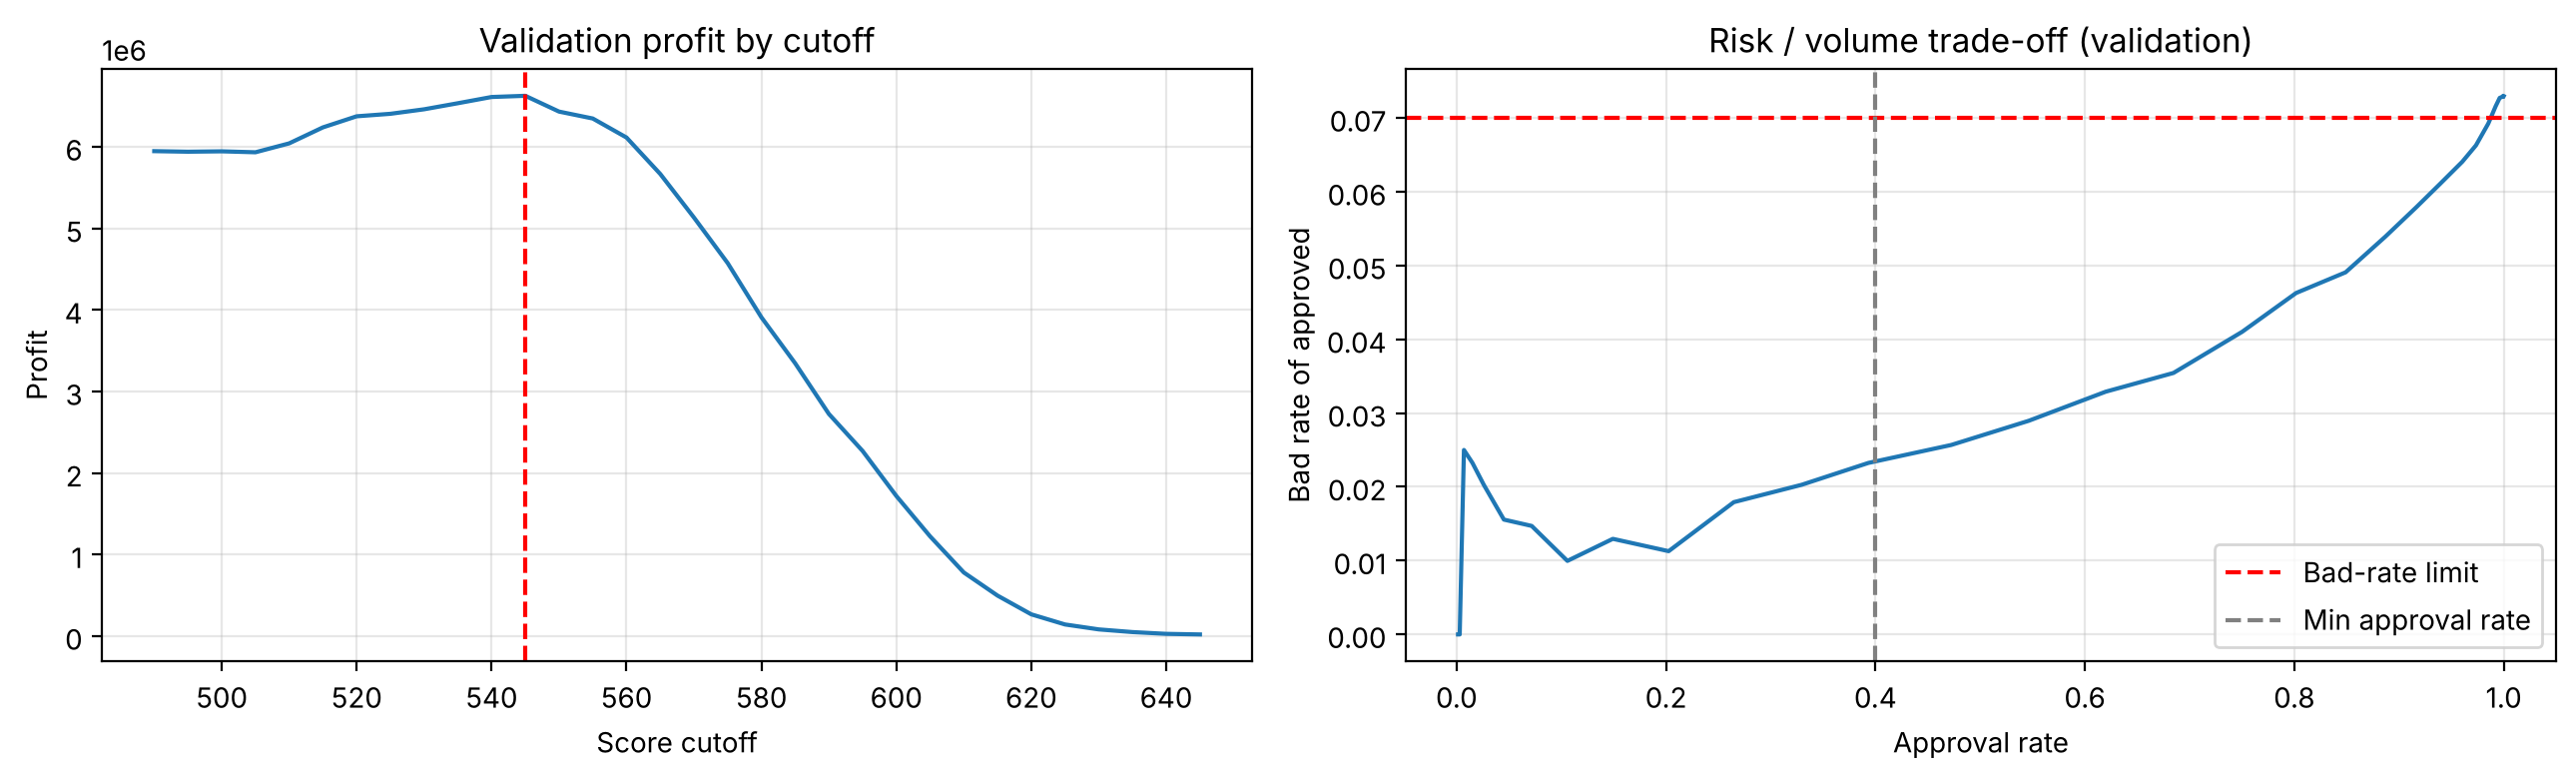

In [16]:
LGD, MARGIN = CONFIG["lgd"], CONFIG["net_margin"]
print(f"Break-even PD = margin / (margin + LGD) = {MARGIN / (MARGIN + LGD):.1%}  (approving above this PD loses money on average)")


def profit_vector(d, lgd=LGD, margin=MARGIN):
    loan, y = d["loan_amount"].to_numpy(), d[TARGET].to_numpy()
    return np.where(y == 1, -lgd * loan, margin * loan)


def scan_cutoffs(d, lgd=LGD, margin=MARGIN):
    s, y, pv = d["score"].to_numpy(), d[TARGET].to_numpy(), profit_vector(d, lgd, margin)
    rows = []
    for c in np.arange(np.floor(s.min() / 5) * 5, np.ceil(s.max() / 5) * 5 + 5, 5):
        a = s >= c
        if a.sum() > 0:
            rows.append({"cutoff": c, "approval_rate": a.mean(), "bad_rate_approved": y[a].mean(), "profit": pv[a].sum()})
    return pd.DataFrame(rows)


def best_cutoff(scan):
    ok = scan[(scan["approval_rate"] >= CONFIG["min_approval_rate"]) &
              (scan["bad_rate_approved"] <= CONFIG["max_bad_rate_approved"])]
    feasible = len(ok) > 0
    return (ok if feasible else scan).sort_values("profit", ascending=False).iloc[0], feasible


scan_valid = scan_cutoffs(valid)
best, feasible = best_cutoff(scan_valid)
CUTOFF = float(best["cutoff"])
print("Constraints satisfiable:", feasible)
print(best.to_frame("chosen cutoff (validation)").T)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(scan_valid["cutoff"], scan_valid["profit"])
ax[0].axvline(CUTOFF, color="red", ls="--"); ax[0].set_title("Validation profit by cutoff")
ax[0].set_xlabel("Score cutoff"); ax[0].set_ylabel("Profit")
ax[1].plot(scan_valid["approval_rate"], scan_valid["bad_rate_approved"])
ax[1].axhline(CONFIG["max_bad_rate_approved"], color="red", ls="--", label="Bad-rate limit")
ax[1].axvline(CONFIG["min_approval_rate"], color="gray", ls="--", label="Min approval rate")
ax[1].set_xlabel("Approval rate"); ax[1].set_ylabel("Bad rate of approved"); ax[1].legend()
ax[1].set_title("Risk / volume trade-off (validation)")
plt.tight_layout()
plt.show()

In [17]:
# ---- Judge the policy once on the out-of-time test set
def policy_row(name, approve, d):
    pv = profit_vector(d)
    return {"policy": name, "approval_rate": approve.mean(), "bad_rate_approved": d[TARGET].to_numpy()[approve].mean(),
            "profit": pv[approve].sum(), "profit_per_applicant": pv[approve].sum() / len(d)}


approve_sc = (test["score"] >= CUTOFF).to_numpy()
n_app = int(approve_sc.sum())
approve_base = np.zeros(len(test), dtype=bool)
approve_base[np.argsort(baseline_risk(test).to_numpy())[:n_app]] = True       # same volume, rule-based ranking

POLICY_TEST = pd.DataFrame([
    policy_row("Approve all", np.ones(len(test), dtype=bool), test),
    policy_row("Baseline rule, same volume", approve_base, test),
    policy_row("Scorecard cutoff", approve_sc, test),
]).set_index("policy")
display(POLICY_TEST)

PROFIT_UPLIFT = POLICY_TEST.loc["Scorecard cutoff", "profit"] - POLICY_TEST.loc["Approve all", "profit"]
print(f"Profit uplift vs approve-all on test: {PROFIT_UPLIFT:,.0f}")

,approval_rate,bad_rate_approved,profit,profit_per_applicant
policy,,,,
Approve all,1.0000,0.0770,"11,269,140.0000",987.4816
"Baseline rule, same volume",0.8199,0.0548,"12,608,610.0000","1,104.8554"
Scorecard cutoff,0.8199,0.0494,"13,211,740.0000","1,157.7059"


Profit uplift vs approve-all on test: 1,942,600


In [18]:
# ---- Sensitivity: how does the optimal cutoff move with LGD and margin?
rows = []
for lgd in (0.4, 0.6, 0.8):
    for mg in (0.06, 0.10, 0.14):
        b, ok = best_cutoff(scan_cutoffs(valid, lgd, mg))
        a = (test["score"] >= b["cutoff"]).to_numpy()
        rows.append({"LGD": lgd, "margin": mg, "cutoff": b["cutoff"], "constraints_ok": ok,
                     "test_profit": profit_vector(test, lgd, mg)[a].sum()})
SENS = pd.DataFrame(rows)
display(SENS.pivot(index="LGD", columns="margin", values="cutoff").rename_axis(columns="margin -> optimal cutoff"))

# ---- Stress: PD shocks, expected profit at the current vs a tightened cutoff
rows = []
loan = test["loan_amount"].to_numpy()
for mult in (1.0, 1.25, 1.5, 2.0):
    p = np.clip(test["pd"].to_numpy() * mult, 0, 1)
    exp_profit = (1 - p) * MARGIN * loan - p * LGD * loan
    row = {"PD multiplier": mult}
    for label, c in (("current cutoff", CUTOFF), ("cutoff + 20", CUTOFF + 20)):
        row[f"expected profit, {label}"] = exp_profit[(test["score"] >= c).to_numpy()].sum()
    rows.append(row)
STRESS = pd.DataFrame(rows).set_index("PD multiplier")
STRESS

margin -> optimal cutoff,0.0600,0.1000,0.1400
LGD,,,
0.4000,545.0000,520.0000,520.0000
0.6000,560.0000,545.0000,520.0000
0.8000,560.0000,545.0000,540.0000


,"expected profit, current cutoff","expected profit, cutoff + 20"
PD multiplier,,
1.0000,"13,021,825.2690","10,635,070.9135"
1.2500,"11,271,001.5863","9,812,261.1419"
1.5000,"9,520,177.9036","8,989,451.3703"
2.0000,"6,018,530.5381","7,343,831.8271"


In [19]:
# ---- Decision rules and risk-based pricing (illustrative pricing inputs)
REVIEW_MARGIN = 15                       # grey zone just below the cutoff goes to a human underwriter
POLICY = {"cutoff": CUTOFF, "review_margin": REVIEW_MARGIN}


def decide(score, cutoff=CUTOFF, review_margin=REVIEW_MARGIN):
    return np.select([score >= cutoff, score >= cutoff - review_margin], ["APPROVE", "MANUAL_REVIEW"], default="DECLINE")


test["decision"] = decide(test["score"].to_numpy())
display(test["decision"].value_counts(normalize=True).to_frame("share of applicants"))

FUNDING, OPEX, TARGET_SPREAD = 0.04, 0.02, 0.02
appr = test[test["score"] >= CUTOFF].copy()
appr["band"] = pd.qcut(appr["score"], 4, labels=["D (lowest)", "C", "B", "A (best)"])
pricing = appr.groupby("band", observed=True).agg(applicants=("score", "size"), avg_score=("score", "mean"),
                                                  avg_pd=("pd", "mean"), observed_default=(TARGET, "mean"))
pricing["suggested_apr"] = FUNDING + OPEX + TARGET_SPREAD + pricing["avg_pd"] * LGD
print("Risk-based pricing bands among approved applicants (test)")
pricing

,share of applicants
decision,
APPROVE,0.8199
MANUAL_REVIEW,0.1122
DECLINE,0.0679


Risk-based pricing bands among approved applicants (test)


,applicants,avg_score,avg_pd,observed_default,suggested_apr
band,,,,,
D (lowest),2344,553.8172,0.0911,0.0798,0.1347
C,2335,568.9932,0.0558,0.0604,0.1135
B,2339,583.6290,0.0344,0.0342,0.1007
A (best),2339,605.4094,0.0173,0.0231,0.0904


---
## Section 4. Deployment (TDSP stage 4)

| | Content |
|---|---|
| **Input** | Validated scorecard, decision policy, infrastructure and audit requirements |
| **Processing** | Export model as plain JSON (no pickle), input validation, scoring service function, drift monitoring, circuit breaker, model card |
| **Output** | Versioned artifacts, scoring function, monitoring table and alert rules, model card |

Run in **shadow mode** (score live applicants, do not act on the score) before turning on automated decisions.

In [20]:
ART = Path(CONFIG["artifact_dir"])
ART.mkdir(exist_ok=True)

(ART / "scorecard_spec.json").write_text(json.dumps(spec, indent=2))
(ART / "policy.json").write_text(json.dumps(POLICY, indent=2))

# Parity test: reloaded JSON model must reproduce notebook scores exactly
loaded = ScorecardModel.from_json(ART / "scorecard_spec.json")
assert np.allclose(loaded.score(test), test["score"]), "Parity test failed"
print("Parity test passed. Artifacts:", sorted(p.name for p in ART.iterdir()))

Parity test passed. Artifacts: ['policy.json', 'scorecard_spec.json']


In [21]:
REQUIRED = ["age", "income", "employment_years", "credit_history_years", "debt_to_income", "credit_utilization",
            "num_delinquencies_2y", "num_inquiries_6m", "num_open_accounts", "loan_amount", "loan_term", "home_ownership"]
VALID_RANGES = {"age": (18, 100), "income": (1, 5e7), "debt_to_income": (0, 1.5), "credit_utilization": (0, 1.5),
                "loan_amount": (100, 5e6)}


def score_applicants(applications, mdl=loaded, policy=POLICY):
    missing = [c for c in REQUIRED if c not in applications.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    d = applications.copy()
    d["loan_to_income"] = d["loan_amount"] / d["income"]
    bad_input = pd.Series(False, index=d.index)
    for c, (lo, hi) in VALID_RANGES.items():
        bad_input |= (d[c] < lo) | (d[c] > hi)                 # NaN is allowed: WoE has a Missing bin
    out = pd.DataFrame({"score": mdl.score(d), "pd": mdl.predict_pd(d)}, index=d.index)
    out["decision"] = decide(out["score"].to_numpy(), policy["cutoff"], policy["review_margin"])
    out.loc[bad_input, "decision"] = "MANUAL_REVIEW"          # never auto-decide on invalid inputs
    out["reason"] = np.where(bad_input, "input out of range", "")
    return out


sample = test.head(8)[REQUIRED + ["applicant_id"]].reset_index(drop=True)
sample.loc[2, "income"] = -5                                  # simulate a bad record
display(pd.concat([sample[["applicant_id"]], score_applicants(sample)], axis=1))

,applicant_id,score,pd,decision,reason
0,12680,578.2318,0.0408,APPROVE,
1,14886,582.2604,0.0357,APPROVE,
2,20093,579.4415,0.0392,MANUAL_REVIEW,input out of range
3,39414,587.7891,0.0296,APPROVE,
4,34450,590.0917,0.0274,APPROVE,
5,38706,580.4591,0.0379,APPROVE,
6,5253,563.0135,0.0672,APPROVE,
7,23135,614.3640,0.0120,APPROVE,


,n,score_psi,max_feature_psi,worst_feature,approval_rate,mean_pd,status,routing
2023-07,982,0.0149,0.0848,credit_utilization,0.8371,0.0696,GREEN,AUTO_DECISION
2023-08,984,0.0220,0.1415,credit_utilization,0.8262,0.0744,AMBER,AUTO_DECISION
2023-09,952,0.0162,0.1375,credit_utilization,0.8225,0.0752,AMBER,AUTO_DECISION
2023-10,986,0.0120,0.0977,credit_utilization,0.8174,0.0733,GREEN,AUTO_DECISION
2023-11,875,0.0290,0.0913,credit_utilization,0.8137,0.0758,GREEN,AUTO_DECISION
2023-12,975,0.0178,0.1131,credit_utilization,0.8144,0.0745,AMBER,AUTO_DECISION
2024-01,946,0.0108,0.1026,credit_utilization,0.8436,0.0702,AMBER,AUTO_DECISION
2024-02,867,0.0254,0.1237,credit_utilization,0.8039,0.0750,AMBER,AUTO_DECISION
2024-03,940,0.0318,0.0967,credit_utilization,0.7851,0.0783,GREEN,AUTO_DECISION
2024-04,944,0.0252,0.1296,credit_utilization,0.8125,0.0769,AMBER,AUTO_DECISION


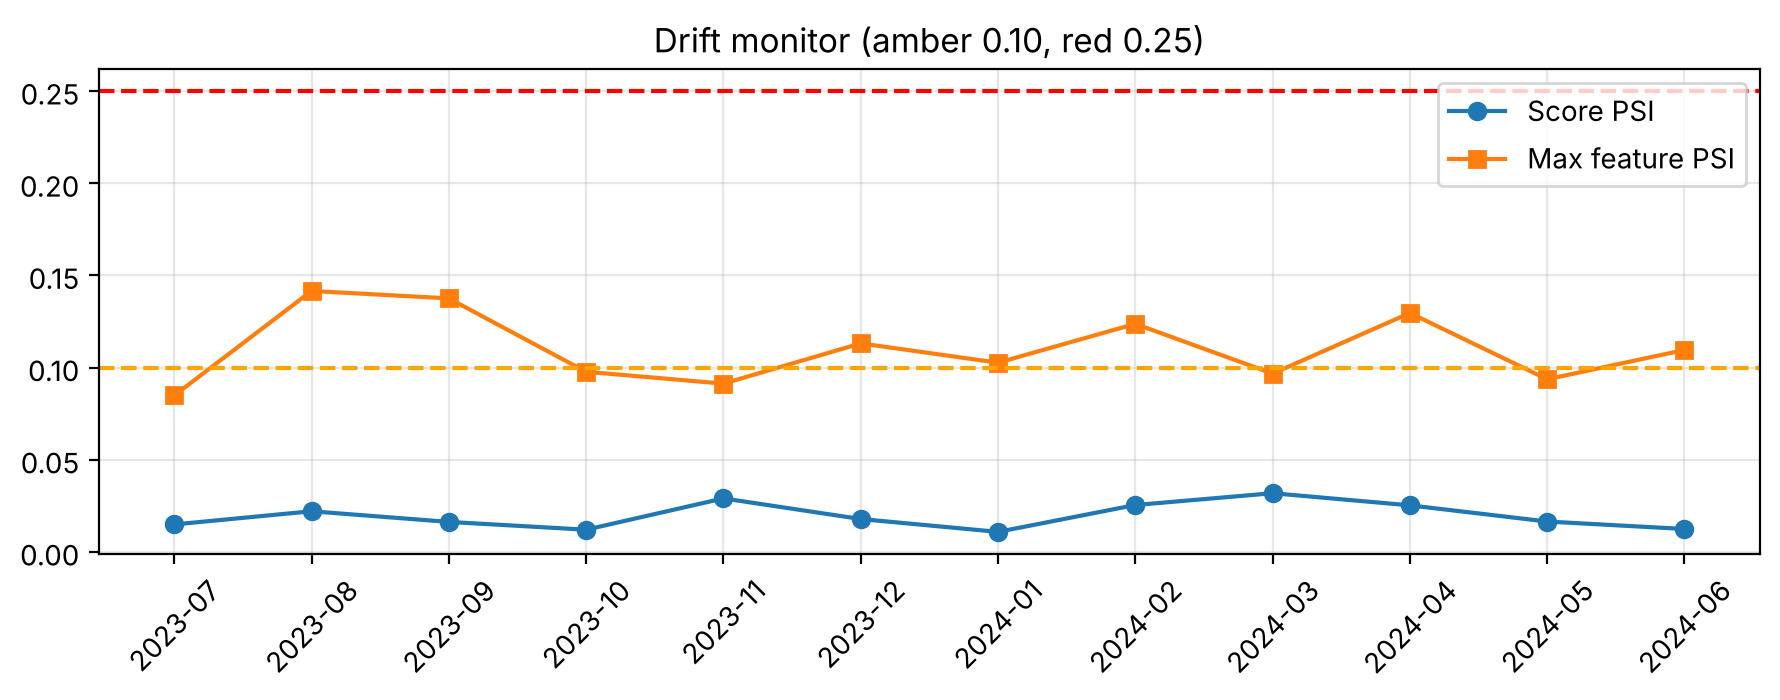

In [22]:
# ---- Monitoring: population drift and portfolio behavior by month on the live (test) period
REF_APPROVAL = float((valid["score"] >= CUTOFF).mean())


def monitor(ref, cur):
    sp = psi_numeric(ref["score"], cur["score"])
    fp = feature_psi(ref, cur, SELECTED)
    appr_rate = float((cur["score"] >= CUTOFF).mean())
    red = sp > 0.25 or fp.max() > 0.25 or abs(appr_rate - REF_APPROVAL) > 0.10
    amber = sp > 0.10 or fp.max() > 0.10
    return {"n": len(cur), "score_psi": sp, "max_feature_psi": fp.max(), "worst_feature": fp.idxmax(),
            "approval_rate": appr_rate, "mean_pd": cur["pd"].mean(),
            "status": "RED" if red else "AMBER" if amber else "GREEN"}


MONITOR = pd.DataFrame({str(p): monitor(train, g) for p, g in test.groupby(test[DATE].dt.to_period("M"))}).T
MONITOR["routing"] = np.where(MONITOR["status"] == "RED", "ALL_TO_MANUAL_REVIEW", "AUTO_DECISION")
display(MONITOR)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(MONITOR.index, MONITOR["score_psi"].astype(float), marker="o", label="Score PSI")
ax.plot(MONITOR.index, MONITOR["max_feature_psi"].astype(float), marker="s", label="Max feature PSI")
ax.axhline(0.10, color="orange", ls="--"); ax.axhline(0.25, color="red", ls="--")
ax.set_title("Drift monitor (amber 0.10, red 0.25)"); ax.legend(); plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

In [23]:
# ---- Model card
test_metrics = evaluate(test[TARGET], test["pd"])
MODEL_CARD = {
    "model": "Retail credit scorecard (logistic regression on WoE features)",
    "purpose": "Estimate 12-month probability of default for loan application decisions",
    "training_window": [str(train[DATE].min().date()), str(train[DATE].max().date())],
    "validation_window": [str(valid[DATE].min().date()), str(valid[DATE].max().date())],
    "out_of_time_test_window": [str(test[DATE].min().date()), str(test[DATE].max().date())],
    "features": SELECTED,
    "scaling": {"base_score": CONFIG["base_score"], "base_odds": CONFIG["base_odds"], "pdo": CONFIG["pdo"]},
    "performance_test": {k: float(v) for k, v in test_metrics.items()},
    "policy": POLICY,
    "limitations": ["Trained on approved-loan outcomes only (no reject inference)",
                    "Synthetic data in this notebook: re-validate on real portfolio data",
                    "Legal review needed for any use of age or other sensitive attributes"],
    "monitoring": "Monthly PSI on score and features; RED status routes all applications to manual review",
    "retrain_triggers": ["score PSI > 0.25", "test AUC falls more than 0.03 below validation", "policy or product change"],
}
(ART / "model_card.json").write_text(json.dumps(MODEL_CARD, indent=2))
print(json.dumps(MODEL_CARD, indent=2)[:1500], "...")

{
  "model": "Retail credit scorecard (logistic regression on WoE features)",
  "purpose": "Estimate 12-month probability of default for loan application decisions",
  "training_window": [
    "2021-01-01",
    "2022-12-31"
  ],
  "validation_window": [
    "2023-01-01",
    "2023-06-30"
  ],
  "out_of_time_test_window": [
    "2023-07-01",
    "2024-06-30"
  ],
  "features": [
    "debt_to_income",
    "num_delinquencies_2y",
    "credit_history_years",
    "credit_utilization",
    "loan_term",
    "home_ownership",
    "num_inquiries_6m"
  ],
  "scaling": {
    "base_score": 600,
    "base_odds": 50,
    "pdo": 20
  },
  "performance_test": {
    "AUC": 0.7323520952136235,
    "Gini": 0.4647041904272471,
    "KS": 0.34118870353503
  },
  "policy": {
    "cutoff": 545.0,
    "review_margin": 15
  },
  "limitations": [
    "Trained on approved-loan outcomes only (no reject inference)",
    "Synthetic data in this notebook: re-validate on real portfolio data",
    "Legal review needed 

---
## Section 5. Customer acceptance (TDSP stage 5)

| | Content |
|---|---|
| **Input** | Out-of-time results, monitoring logs, the acceptance criteria fixed in Section 1 |
| **Processing** | Automated pass/fail check of every criterion; independent validation and compliance review; handover |
| **Output** | Sign-off decision or remediation list, lifecycle plan, and a feedback list that starts the next iteration at Section 1 |

In [24]:
auc_train = evaluate(train[TARGET], train["pd"])["AUC"]
auc_test = test_metrics["AUC"]
base_test_auc = BASELINE.loc["test", "AUC"]
score_psi_test = psi_numeric(train["score"], test["score"])
approved_bad_rate = POLICY_TEST.loc["Scorecard cutoff", "bad_rate_approved"]

checks = [
    ("Test AUC", auc_test, ">=", ACCEPTANCE["test_auc_min"]),
    ("Test KS", test_metrics["KS"], ">=", ACCEPTANCE["test_ks_min"]),
    ("AUC gap train - test", auc_train - auc_test, "<=", ACCEPTANCE["auc_gap_train_test_max"]),
    ("AUC uplift vs baseline rule", auc_test - base_test_auc, ">=", ACCEPTANCE["auc_uplift_vs_baseline_min"]),
    ("Calibration gap |mean PD - observed|", abs(test["pd"].mean() - test[TARGET].mean()), "<=", ACCEPTANCE["calibration_gap_max"]),
    ("Score PSI, test vs train", score_psi_test, "<=", ACCEPTANCE["score_psi_max"]),
    ("Bad rate of approved", approved_bad_rate, "<=", ACCEPTANCE["approved_bad_rate_max"]),
    ("Profit uplift vs approve-all", PROFIT_UPLIFT, ">=", ACCEPTANCE["profit_uplift_vs_approve_all_min"]),
]
ACCEPT = pd.DataFrame(checks, columns=["criterion", "value", "rule", "threshold"])
ACCEPT["pass"] = [(v >= t) if r == ">=" else (v <= t) for _, v, r, t in checks]
display(ACCEPT)

verdict = "ACCEPT: proceed to shadow mode" if ACCEPT["pass"].all() else "REMEDIATE: " + ", ".join(ACCEPT.loc[~ACCEPT["pass"], "criterion"])
print("Verdict:", verdict)

,criterion,value,rule,threshold,pass
0,Test AUC,0.7324,>=,0.7000,True
1,Test KS,0.3412,>=,0.3000,True
2,AUC gap train - test,-0.0004,<=,0.0300,True
3,AUC uplift vs baseline rule,0.0260,>=,0.0300,False
4,Calibration gap |mean PD - observed|,0.0031,<=,0.0100,True
5,"Score PSI, test vs train",0.0102,<=,0.2500,True
6,Bad rate of approved,0.0494,<=,0.0700,True
7,Profit uplift vs approve-all,"1,942,600.0000",>=,0.0000,True


Verdict: REMEDIATE: AUC uplift vs baseline rule


### Feedback loop: start of the next iteration (back to Section 1)

Typical items to carry into the next cycle:

1. **Reject inference.** Outcomes exist only for approved loans; estimate behavior of declined applicants before widening approvals.
2. **Richer data.** Add bureau trend variables, cash-flow data, and macro indicators; re-run Sections 2 and 3B.
3. **Monotonic challenger.** Re-test gradient boosting with monotonic constraints and explainability (SHAP) if lift justifies it.
4. **Fairness and compliance testing.** Test outcomes across protected groups and confirm which attributes may legally be used.
5. **Recalibration policy.** Recalibrate the intercept when score PSI is amber for three consecutive months; rebuild when red.
6. **Live vs backtest.** After shadow mode, compare realized defaults with predicted PD by score band and update Section 1 thresholds.